In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv('../datasets/dataset_clean.csv')
print("Setup ready!")

Setup ready!


In [10]:
# Rupiah formatting
def to_rupiah(num):
    if pd.isna(num):
        return "-"
    return f"Rp {num:,.0f}".replace(",", ".")

# 1. Variasi Gaji berdasarkan Posisi Pekerjaan
gaji_posisi = df.groupby('posisi_pekerjaan_clean')['gaji_pokok_bulanan_idr'].agg(
    gaji_min='min',
    gaji_median='median',
    gaji_mean='mean',
    gaji_max='max'
).sort_values(by='gaji_median', ascending=True)

print("=== Ringkasan Gaji Bulanan per Posisi ===")
# display(gaji_posisi)

gaji_posisi_rp = gaji_posisi.map(to_rupiah)
display(gaji_posisi_rp)

# 2. Variasi Gaji berdasarkan Skala Perusahaan
gaji_skala = df.groupby('skala_perusahaan')['gaji_pokok_bulanan_idr'].agg(
    ['min', 'median', 'mean', 'max']
).sort_values(by='median', ascending=True)

print("\n=== Ringkasan Gaji Bulanan per Skala Perusahaan ===")
gaji_skala_rp = gaji_skala.map(to_rupiah)
display(gaji_skala_rp)

=== Ringkasan Gaji Bulanan per Posisi ===


,gaji_min,gaji_median,gaji_mean,gaji_max
posisi_pekerjaan_clean,,,,
Data Engineer,Rp 6.000.000,Rp 25.500.000,Rp 33.434.363,Rp 110.000.000
Product Manager,Rp 6.000.000,Rp 25.500.000,Rp 33.272.938,Rp 110.000.000
UI/UX Designer,Rp 5.500.000,Rp 25.500.000,Rp 32.710.872,Rp 110.000.000
Frontend Engineer,Rp 5.500.000,Rp 26.000.000,Rp 34.137.572,Rp 110.000.000
Fullstack Engineer,Rp 5.500.000,Rp 26.000.000,Rp 33.858.857,Rp 110.000.000
QA / Test Engineer,Rp 5.500.000,Rp 26.000.000,Rp 33.878.736,Rp 110.000.000
Machine Learning / AI Engineer,Rp 6.000.000,Rp 26.500.000,Rp 34.149.218,Rp 110.000.000
Cybersecurity Specialist,Rp 6.000.000,Rp 26.500.000,Rp 33.702.999,Rp 110.000.000
Technical Writer,Rp 5.500.000,Rp 27.000.000,Rp 33.781.371,Rp 110.000.000



=== Ringkasan Gaji Bulanan per Skala Perusahaan ===


,min,median,mean,max
skala_perusahaan,,,,
Software House / IT Agency,Rp 5.500.000,Rp 21.000.000,Rp 27.246.449,Rp 110.000.000
Startup Early-Stage Seed/Pre-A,Rp 5.500.000,Rp 22.000.000,Rp 28.650.470,Rp 110.000.000
BUMN Teknologi / Telekomunikasi,Rp 6.500.000,Rp 23.500.000,Rp 30.769.821,Rp 110.000.000
Startup Growth Series B/C,Rp 6.500.000,Rp 25.500.000,Rp 32.144.720,Rp 110.000.000
Decacorn / Unicorn Lokal,Rp 7.000.000,Rp 29.000.000,Rp 37.322.060,Rp 110.000.000
Perusahaan FinTech / Bank Digital,Rp 7.500.000,Rp 30.000.000,Rp 37.941.802,Rp 110.000.000
Perusahaan Remote Global / Luar Negeri,Rp 9.500.000,Rp 36.500.000,Rp 46.396.552,Rp 110.000.000


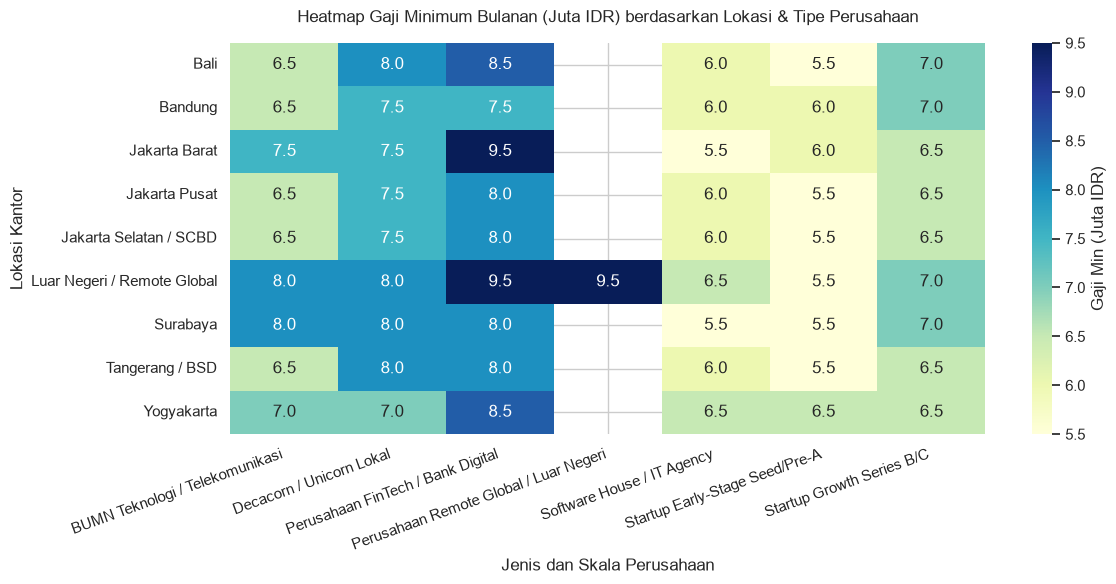

In [4]:
plt.figure(figsize=(12, 6))

# Buat Pivot Table (Gaji Minimum dalam Juta IDR)
pivot_min_salary = df.pivot_table(
    index='lokasi_kantor', 
    columns='skala_perusahaan', 
    values='gaji_pokok_bulanan_idr', 
    aggfunc='min'
) / 1e6

sns.heatmap(pivot_min_salary, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Gaji Min (Juta IDR)'})
plt.title('Heatmap Gaji Minimum Bulanan (Juta IDR) berdasarkan Lokasi & Tipe Perusahaan', fontsize=12, pad=15)
plt.xlabel('Jenis dan Skala Perusahaan')
plt.ylabel('Lokasi Kantor')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()